# Chapter 15 · Asian options: interactive demos

Companion to Chapter 15 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/15-asian.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The default is the course's monthly Asian call: the test case $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$,
with twelve equally weighted fixings $t_j=j/12$. Its arithmetic price is $4.5612893$ (Example 15.11) and its
geometric twin $4.40286$ (Proposition 15.2). Reference prices below come from the recursion (15.4) on a coarse grid
(accurate to about $10^{-9}$ here).

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import warnings
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import asian as A, bs
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style
from mfe230d.variance import control_variate, regression_control_variates

warnings.simplefilter("ignore")
use_style()
GREEN, PURPLE = "#1BAF7A", "#6250D6"
S, r, y = 100.0, 0.01, 0.02

def dates(m, T):
    return np.arange(1, m + 1) * T / m

def ref(K, t, sigma, T):
    return A.recursion_price(S, K, t, r, y, sigma, T=T, N=1201, nq=32)

## 1. Arithmetic, geometric and European calls

Proposition 15.1: the geometric call is a lower bound for the arithmetic one, the strip of calls
$D\sum_jw_j\mathbb E(S_{t_j}-K)^+$ an upper bound; with one fixing all three coincide with the European call.
Proposition 15.2 prices the geometric call exactly, and its effective volatility $\sqrt{v_G/T}$ tends to
$\sigma/\sqrt3$ as $m$ grows. The dashed line is the conditioning lower bound $L(x^*)$ of Proposition 15.10: on this
scale it is indistinguishable from the arithmetic price.

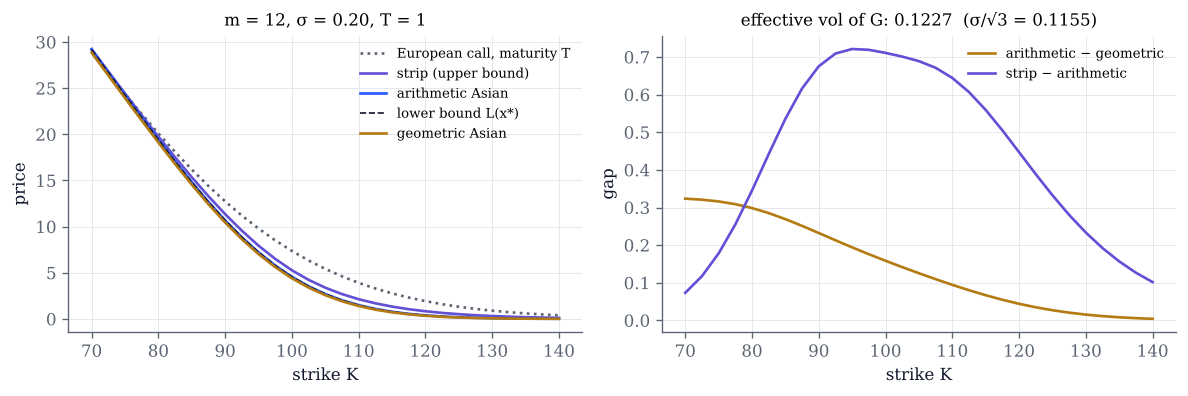

In [2]:
def prices(m=12, sigma=0.2, T=1.0):
    t = dates(m, T)
    Ks = np.linspace(70, 140, 29)
    ar = np.array([ref(K, t, sigma, T) for K in Ks])
    ge = np.array([A.geometric_price(S, K, t, r, y, sigma) for K in Ks])
    st = np.array([A.strip_bound(S, K, t, r, y, sigma) for K in Ks])
    lb = np.array([A.conditioning_lower_bound(S, K, t, r, y, sigma) for K in Ks])
    eu = bs.call(S, Ks, T, r, y, sigma)
    _, v = A.geometric_law(S, t, r, y, sigma)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(Ks, eu, color=GREY, ls=":", label="European call, maturity T")
    ax.plot(Ks, st, color=PURPLE, label="strip (upper bound)")
    ax.plot(Ks, ar, color=COBALT, label="arithmetic Asian")
    ax.plot(Ks, lb, color=INK, ls="--", lw=1, label="lower bound L(x*)")
    ax.plot(Ks, ge, color=GOLD, label="geometric Asian")
    ax.set(xlabel="strike K", ylabel="price", title=f"m = {m}, σ = {sigma:.2f}, T = {T:g}")
    ax.legend(fontsize=8)
    bx.plot(Ks, ar - ge, color=GOLD, label="arithmetic − geometric")
    bx.plot(Ks, st - ar, color=PURPLE, label="strip − arithmetic")
    bx.set(xlabel="strike K", ylabel="gap",
           title=f"effective vol of G: {np.sqrt(v / T):.4f}  (σ/√3 = {sigma / np.sqrt(3):.4f})")
    bx.legend(fontsize=8); fig.tight_layout(); plt.show()

prices()

In [3]:
# Explore: set m = 1 (all curves meet), then raise m. Where is the gap between the arithmetic and geometric
# calls largest, and how does it scale with sigma?
interact(prices,
         m=IntSlider(value=12, min=1, max=52, continuous_update=False, description="fixings m"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=1.0, min=0.25, max=5.0, step=0.25, continuous_update=False, description="T"));

## 2. Control variates

As in Figure 15.1 and Proposition 15.4: the standard deviation per path of plain Monte Carlo, of the geometric control
(in-sample coefficient) and of the regression on three controls (geometric, vanilla on the last fixing, strip),
against the strike, all on the same paths. The dotted line is the strike-free bound
$\sqrt{D^2\mathbb E(A-G)^2}$ on the standard deviation of $Y-X^{\mathrm g}$; the title gives the conditional estimator
of Proposition 15.6 at the money, which integrates the geometric direction out exactly.

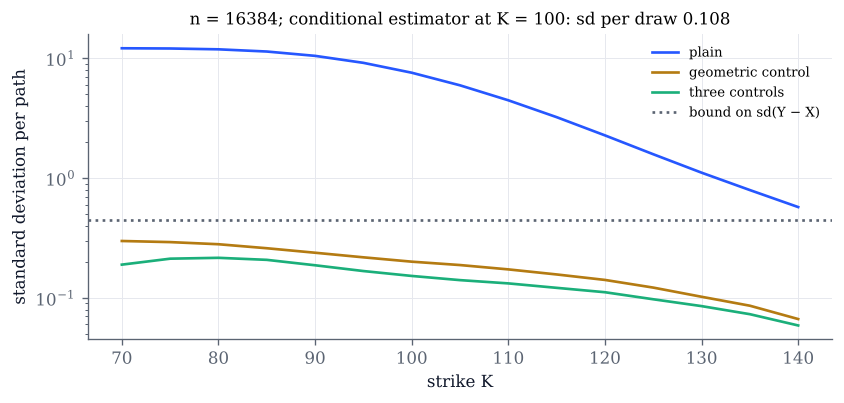

In [4]:
def controls(m=12, sigma=0.2, log2_n=14, seed=15):
    t = dates(m, 1.0)
    n = 2**log2_n
    Z = np.random.default_rng(seed).standard_normal((n, m))
    Ks = np.linspace(70, 140, 15)
    out = []
    for K in Ks:
        s = A.payoff_samples(S, K, t, r, y, sigma, Z=Z)
        mu = A.control_means(S, K, t, r, y, sigma)
        Y = s["arithmetic"]
        g = control_variate(Y, s["geometric"], mu["geometric"])
        X = np.column_stack([s[c] for c in ("geometric", "vanilla", "strip")])
        tr = regression_control_variates(Y, X, [mu[c] for c in ("geometric", "vanilla", "strip")])
        out.append((Y.std(ddof=1), g["se"] * np.sqrt(n), tr["se"] * np.sqrt(n)))
    q = np.array(out)
    cond = A.conditional_samples(S, 100.0, t, Z[:, 1:], r, y, sigma)
    fig, ax = plt.subplots(figsize=(8, 3.3))
    ax.semilogy(Ks, q[:, 0], color=COBALT, label="plain")
    ax.semilogy(Ks, q[:, 1], color=GOLD, label="geometric control")
    ax.semilogy(Ks, q[:, 2], color=GREEN, label="three controls")
    ax.axhline(np.sqrt(A.dispersion_bound(S, t, r, y, sigma)), color=GREY, ls=":", label="bound on sd(Y − X)")
    ax.set(xlabel="strike K", ylabel="standard deviation per path",
           title=f"n = {n}; conditional estimator at K = 100: sd per draw {cond.std(ddof=1):.3f}")
    ax.legend(fontsize=8); plt.show()

controls()

In [5]:
# Explore: how does the geometric control degrade with sigma? Does the number of fixings matter much?
interact(controls,
         m=IntSlider(value=12, min=2, max=52, continuous_update=False, description="fixings m"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         log2_n=IntSlider(value=14, min=10, max=17, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=15, min=0, max=5000, continuous_update=False, description="seed"));

## 3. How accurate are the approximations?

Errors against the reference, as in Table 15.1 and Figure 15.2: two moments (Levy; Turnbull and Wakeman), three moments
(shifted lognormal), the Edgeworth correction (15.3), the first term of Curran's decomposition, the lower bound
$L(x^*)$ and the conditional lognormal approximation (Proposition 15.10). Left: signed errors of the moment methods.
Right: absolute errors on a log scale for all six. The two lower bounds are always below the reference; the others
change sign.

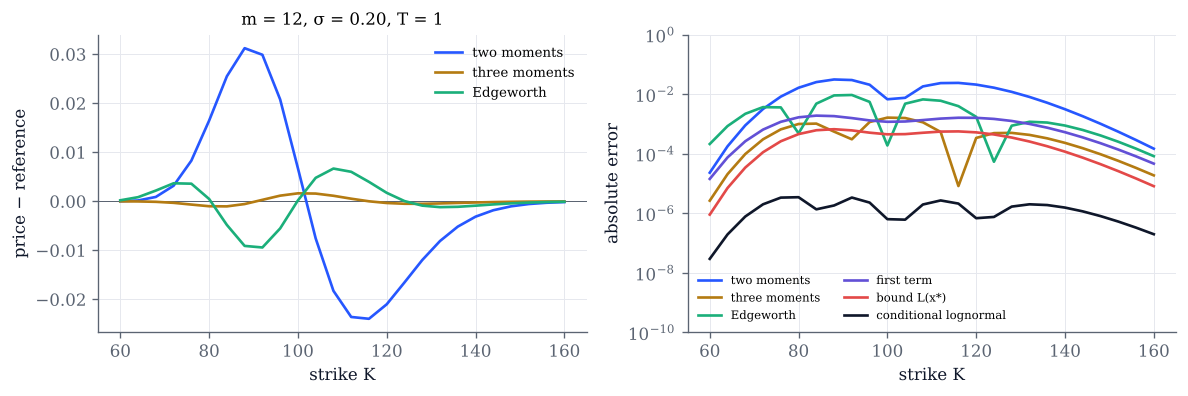

In [6]:
METHODS = [("two moments", A.lognormal_price, COBALT), ("three moments", A.shifted_lognormal_price, GOLD),
           ("Edgeworth", A.edgeworth_price, GREEN), ("first term", A.curran_first_term, PURPLE),
           ("bound L(x*)", A.conditioning_lower_bound, "#E34948"), ("conditional lognormal", A.curran_refined, INK)]

def errors(m=12, sigma=0.2, T=1.0):
    t = dates(m, T)
    Ks = np.linspace(60, 160, 26)
    R = np.array([ref(K, t, sigma, T) for K in Ks])
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.axhline(0, color=GREY, lw=0.6)
    for name, f, col in METHODS:
        e = np.array([f(S, K, t, r, y, sigma) for K in Ks]) - R
        if name in ("two moments", "three moments", "Edgeworth"):
            ax.plot(Ks, e, color=col, label=name)
        bx.semilogy(Ks, np.maximum(np.abs(e), 1e-12), color=col, label=name)
    ax.set(xlabel="strike K", ylabel="price − reference", title=f"m = {m}, σ = {sigma:.2f}, T = {T:g}")
    ax.legend(fontsize=8)
    bx.set(xlabel="strike K", ylabel="absolute error", ylim=(1e-10, 1))
    bx.legend(fontsize=7, ncol=2); fig.tight_layout(); plt.show()

errors()

In [7]:
# Explore: raise sigma or T. Which method degrades first? Does the ranking change with the number of fixings?
interact(errors,
         m=IntSlider(value=12, min=2, max=52, continuous_update=False, description="fixings m"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=1.0, min=0.25, max=5.0, step=0.25, continuous_update=False, description="T"));

## Things to try

- In section 1, set $m=1$ and check that the four curves meet; then set $m=52$ and compare the effective volatility
  of the geometric average with $\sigma/\sqrt3$.
- In section 1, raise $\sigma$ to $0.8$: does the lower bound $L(x^*)$ stay on top of the arithmetic price?
- In section 2, find the volatility at which the geometric control stops giving a factor of ten in standard
  deviation at the money. How much do the two extra controls add there?
- In section 3, with $\sigma=0.6$ and $T=5$, which approximation would you trust for a quote to the cent, and which
  for a risk system that needs a guaranteed lower bound?
- In section 3, compare $m=2$ with $m=12$: why is the error of the conditioning methods so much smaller for few fixings?